## House Prices (Feature Analysis)

In [1]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from IPython.display import display

from house_prices_mlops.pipeline import load_stage
from house_prices_mlops.data_tracker import DataTracker

df_hp = load_stage("train")
tracker = DataTracker.load(df_hp)
target = "SalePrice"


2026-10-11 07:06:36.526 | INFO     | house_prices_mlops.config:<module>:11 - PROJ_ROOT path is: /home/jovyan/notebooks/house_prices_cookiecutter/house-prices-mlops


Only training data is analyzed. Id is retained for traceability and excluded from feature correlations. No transformations or feature selection are applied.

### Numeric Variables vs Target

In [2]:

# FEATURE ANALYSIS - NUMERIC VS TARGET


target = 'SalePrice'

numeric_cols = df_hp.select_dtypes(
    include='number'
).columns

correlation_num = (
    df_hp[numeric_cols]
    .drop(columns=['Id'], errors='ignore').corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

display(correlation_num)


OverallQual      0.785555
GrLivArea        0.695652
GarageCars       0.640991
GarageArea       0.624139
TotalBsmtSF      0.597766
1stFlrSF         0.587883
FullBath         0.552546
TotRmsAbvGrd     0.520388
YearBuilt        0.516501
YearRemodAdd     0.508593
GarageYrBlt      0.480351
MasVnrArea       0.459123
Fireplaces       0.457549
BsmtFinSF1       0.359460
LotFrontage      0.330066
WoodDeckSF       0.329843
2ndFlrSF         0.314030
OpenPorchSF      0.299969
HalfBath         0.280481
LotArea          0.266204
BsmtFullBath     0.226346
BsmtUnfSF        0.222487
BedroomAbvGr     0.156211
EnclosedPorch   -0.149532
KitchenAbvGr    -0.142785
ScreenPorch      0.119172
PoolArea         0.115630
MSSubClass      -0.088081
OverallCond     -0.074391
3SsnPorch        0.051532
BsmtHalfBath    -0.048346
MoSold           0.041890
MiscVal         -0.020179
LowQualFinSF    -0.011189
YrSold          -0.009099
BsmtFinSF2      -0.005731
Name: SalePrice, dtype: float64

#### Strong Correlations (|r| > 0.5)

In [3]:
top_correlation_num = correlation_num[
    correlation_num.abs() > 0.5
]

display(top_correlation_num)


OverallQual     0.785555
GrLivArea       0.695652
GarageCars      0.640991
GarageArea      0.624139
TotalBsmtSF     0.597766
1stFlrSF        0.587883
FullBath        0.552546
TotRmsAbvGrd    0.520388
YearBuilt       0.516501
YearRemodAdd    0.508593
Name: SalePrice, dtype: float64

#### Scatter Plots

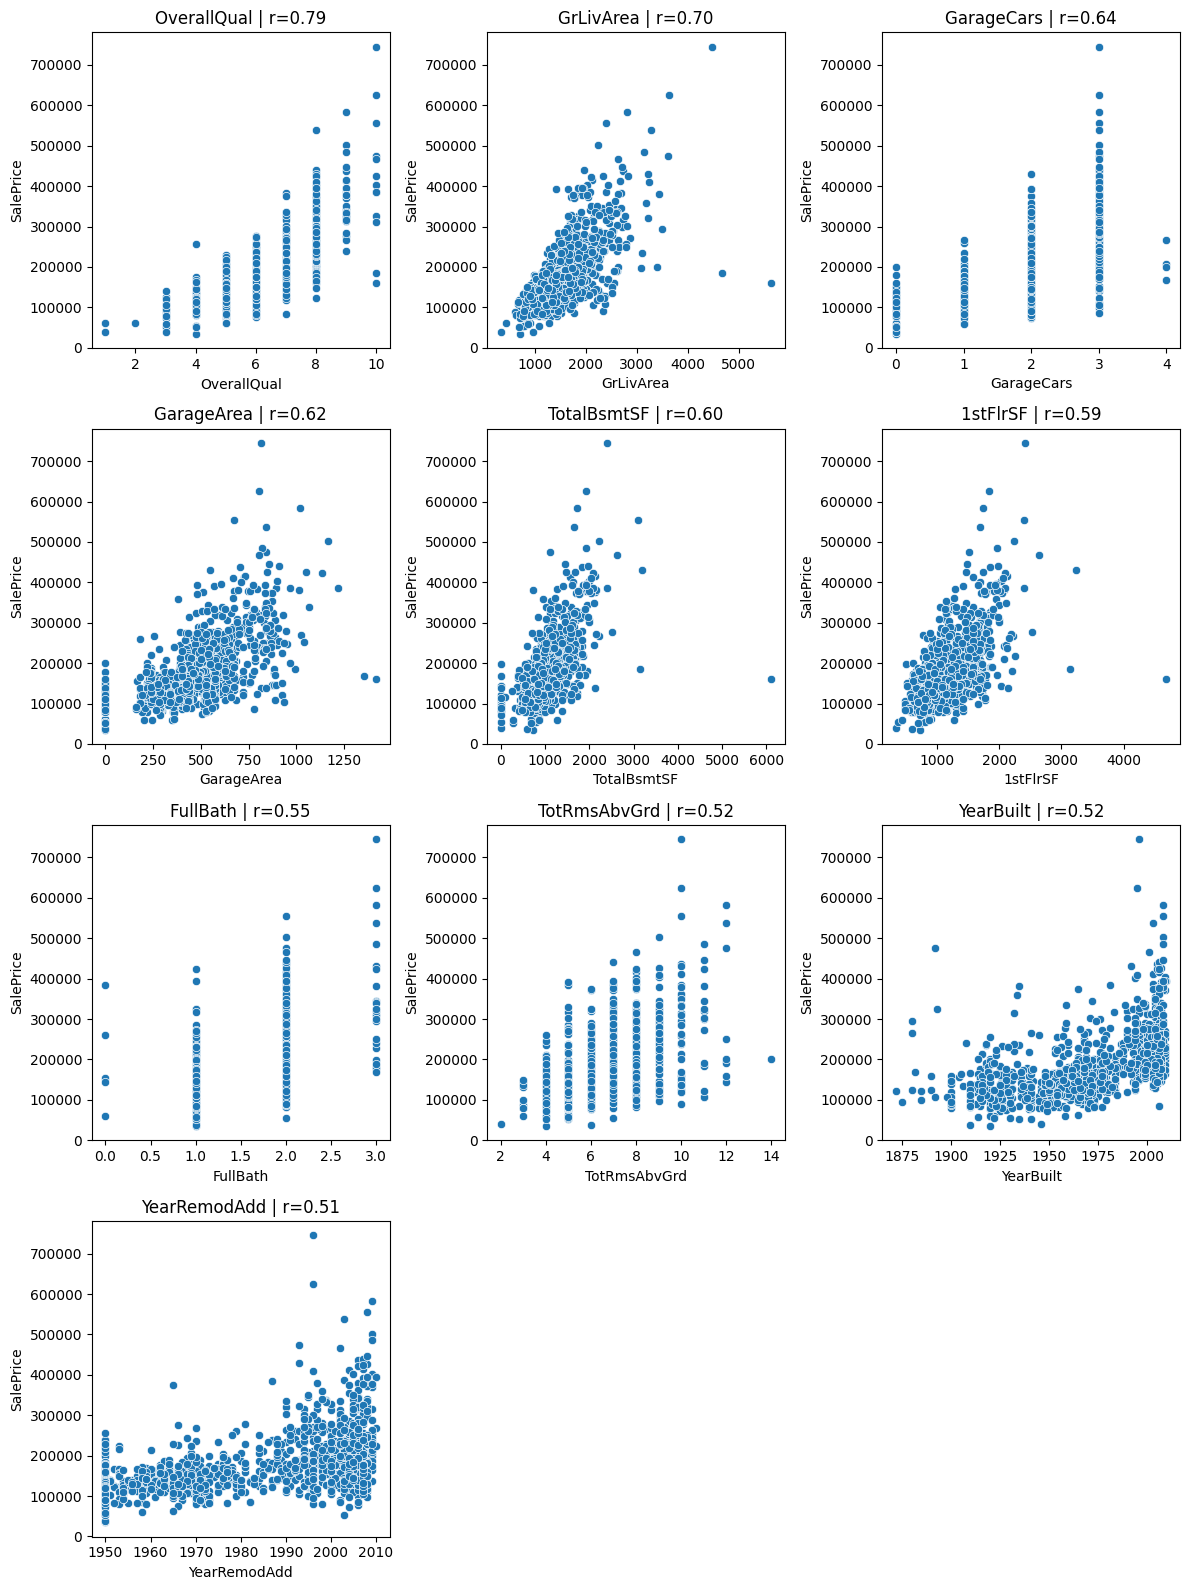

In [4]:
import math

n_cols = 3
n_rows = math.ceil(len(top_correlation_num) / n_cols)

fig, ax = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 4 * n_rows)
)

ax = np.array(ax).flatten()

for index, var in enumerate(top_correlation_num.index):

    sns.scatterplot(
        x=df_hp[var],
        y=df_hp[target],
        ax=ax[index]
    )

    ax[index].set_title(
        f'{var} | r={top_correlation_num[var]:.2f}'
    )

# Quitar ejes sobrantes
for index in range(len(top_correlation_num), len(ax)):
    ax[index].remove()

fig.tight_layout()
plt.show()


#### Findings

In [ ]:
tracker.add_finding(key='gr_liv_area_target_outliers', 
    var='GrLivArea',
    stage='DU - Feature Analysis - Numeric vs Target',
    finding=(
        'Relación positiva fuerte con SalePrice, con observaciones extremas de '
        'GrLivArea elevada que presentan SalePrice inusualmente bajo; '
        'requiere revisar los valores atípicos.'
    )
)


### Categorical Variables vs Target

In [6]:
#Categorical variables vs target
#   -Group effect (Diferencias entre grupos)
#   -Strength of effect (Magnitud de las diferencias)
#   -Ordered patters (Patrones y jerarquias)
#   -Group outliers (Categorias atipicas)


# FEATURE ANALYSIS - CATEGORICAL VS TARGET


target = 'SalePrice'

categorical_vars = tracker.profile.loc[
    tracker.profile['variable_type'].isin(['nominal', 'ordinal']),
    'var'
].tolist()

min_group_pct = 0.01
threshold = int(len(df_hp) * min_group_pct)

categorical_analysis = []

for col in categorical_vars:

    g = (
        df_hp
        .groupby(col, observed=True)[target]
        .agg(['mean', 'median', 'count'])
    )

    n_total = len(df_hp)
    n_categories = g.shape[0]

    min_count = g['count'].min()
    max_count = g['count'].max()

    smallest_group_pct = min_count / n_total

    rare_groups_count = (
        g['count'] < threshold
    ).sum()

    imbalance_ratio = (
        max_count / max(1, min_count)
    )

    # Solo grupos con tamaño suficiente
    g_reliable = g[
        g['count'] >= threshold
    ]

    if g_reliable.empty:
        continue

    # ¿Media o mediana representa mejor los grupos?
    diff_rel = (
        (g_reliable['mean'] - g_reliable['median']).abs()
        / g_reliable['median']
    )

    score = diff_rel.median()

    measure = (
        'median'
        if score > 0.10
        else 'mean'
    )

    values = g_reliable[measure]

    effect = (
        values.max() - values.min()
    )

    categorical_analysis.append({
        'var': col,
        'n_categories': n_categories,
        'reliable_groups': len(g_reliable),
        'min_group_size': min_count,
        'min_group_pct': smallest_group_pct,
        'rare_groups_count': rare_groups_count,
        'imbalance_ratio': imbalance_ratio,
        'target_group_range': effect,
        'measure': measure
    })

categorical_analysis = (
    pd.DataFrame(categorical_analysis)
    .sort_values(
        'target_group_range',
        ascending=False
    )
)

display(categorical_analysis)


,var,n_categories,reliable_groups,min_group_size,min_group_pct,rare_groups_count,imbalance_ratio,target_group_range,measure
14,OverallQual,10,8,1,0.000856,2,311.000000,330389.908654,mean
21,ExterQual,4,4,11,0.009418,0,66.090909,258126.391775,mean
33,KitchenQual,4,4,32,0.027397,0,18.406250,223046.556006,mean
9,Neighborhood,25,21,1,0.000856,4,181.000000,222269.706294,mean
24,BsmtQual,4,4,29,0.024829,0,17.965517,202286.404550,mean
35,FireplaceQu,5,5,16,0.013699,0,19.062500,184476.657738,mean
0,MSSubClass,15,12,3,0.002568,3,144.666667,142645.233333,mean
43,SaleType,9,3,2,0.001712,6,506.000000,129188.344215,mean
18,Exterior1st,15,10,1,0.000856,5,420.000000,126482.266667,mean
44,SaleCondition,6,4,4,0.003425,2,241.000000,117674.930839,mean


#### Reliable Group Comparisons

In [7]:
reliable_comparison = categorical_analysis[
    categorical_analysis['reliable_groups'] >= 2
]

display(
    reliable_comparison.sort_values(
        'target_group_range',
        ascending=False
    )
)


,var,n_categories,reliable_groups,min_group_size,min_group_pct,rare_groups_count,imbalance_ratio,target_group_range,measure
14,OverallQual,10,8,1,0.000856,2,311.000000,330389.908654,mean
21,ExterQual,4,4,11,0.009418,0,66.090909,258126.391775,mean
33,KitchenQual,4,4,32,0.027397,0,18.406250,223046.556006,mean
9,Neighborhood,25,21,1,0.000856,4,181.000000,222269.706294,mean
24,BsmtQual,4,4,29,0.024829,0,17.965517,202286.404550,mean
35,FireplaceQu,5,5,16,0.013699,0,19.062500,184476.657738,mean
0,MSSubClass,15,12,3,0.002568,3,144.666667,142645.233333,mean
43,SaleType,9,3,2,0.001712,6,506.000000,129188.344215,mean
18,Exterior1st,15,10,1,0.000856,5,420.000000,126482.266667,mean
44,SaleCondition,6,4,4,0.003425,2,241.000000,117674.930839,mean


### Feature vs Feature (Multicollinearity)

In [8]:

# FEATURE VS FEATURE - MULTICOLLINEARITY


target = 'SalePrice'
threshold = 0.7

numeric_features = (
    df_hp
    .select_dtypes(include='number')
    .drop(columns=[target, 'Id'], errors='ignore')
)

corr_matrix = numeric_features.corr()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr = (
    upper
    .stack()
    .reset_index()
)

high_corr.columns = [
    'var1',
    'var2',
    'corr'
]

high_corr = (
    high_corr[
        high_corr['corr'].abs() >= threshold
    ]
    .sort_values(
        'corr',
        key=abs,
        ascending=False
    )
)

display(high_corr)


,var1,var2,corr
575,GarageCars,GarageArea,0.882550
330,TotalBsmtSF,1stFlrSF,0.827382
426,GrLivArea,TotRmsAbvGrd,0.820718
183,YearBuilt,GarageYrBlt,0.819557


#### Findings

In [ ]:
correlation_keys = {('GarageCars', 'GarageArea'): 'garage_cars_area_correlation', ('TotalBsmtSF', '1stFlrSF'): 'basement_first_floor_correlation', ('GrLivArea', 'TotRmsAbvGrd'): 'living_area_rooms_correlation', ('YearBuilt', 'GarageYrBlt'): 'house_garage_year_correlation'}

for _, row in high_corr.iterrows():

    tracker.add_finding(key=correlation_keys[(row["var1"], row["var2"])], 
        var=f"{row['var1']} | {row['var2']}",
        stage='DU - Feature Analysis - Multicollinearity',
        finding=(
            f"Se detectó una correlación elevada entre variables "
            f"(r={row['corr']:.3f}); la posible redundancia "
            f"debe evaluarse antes del modelado."
        )
    )


#### Correlation Heatmap

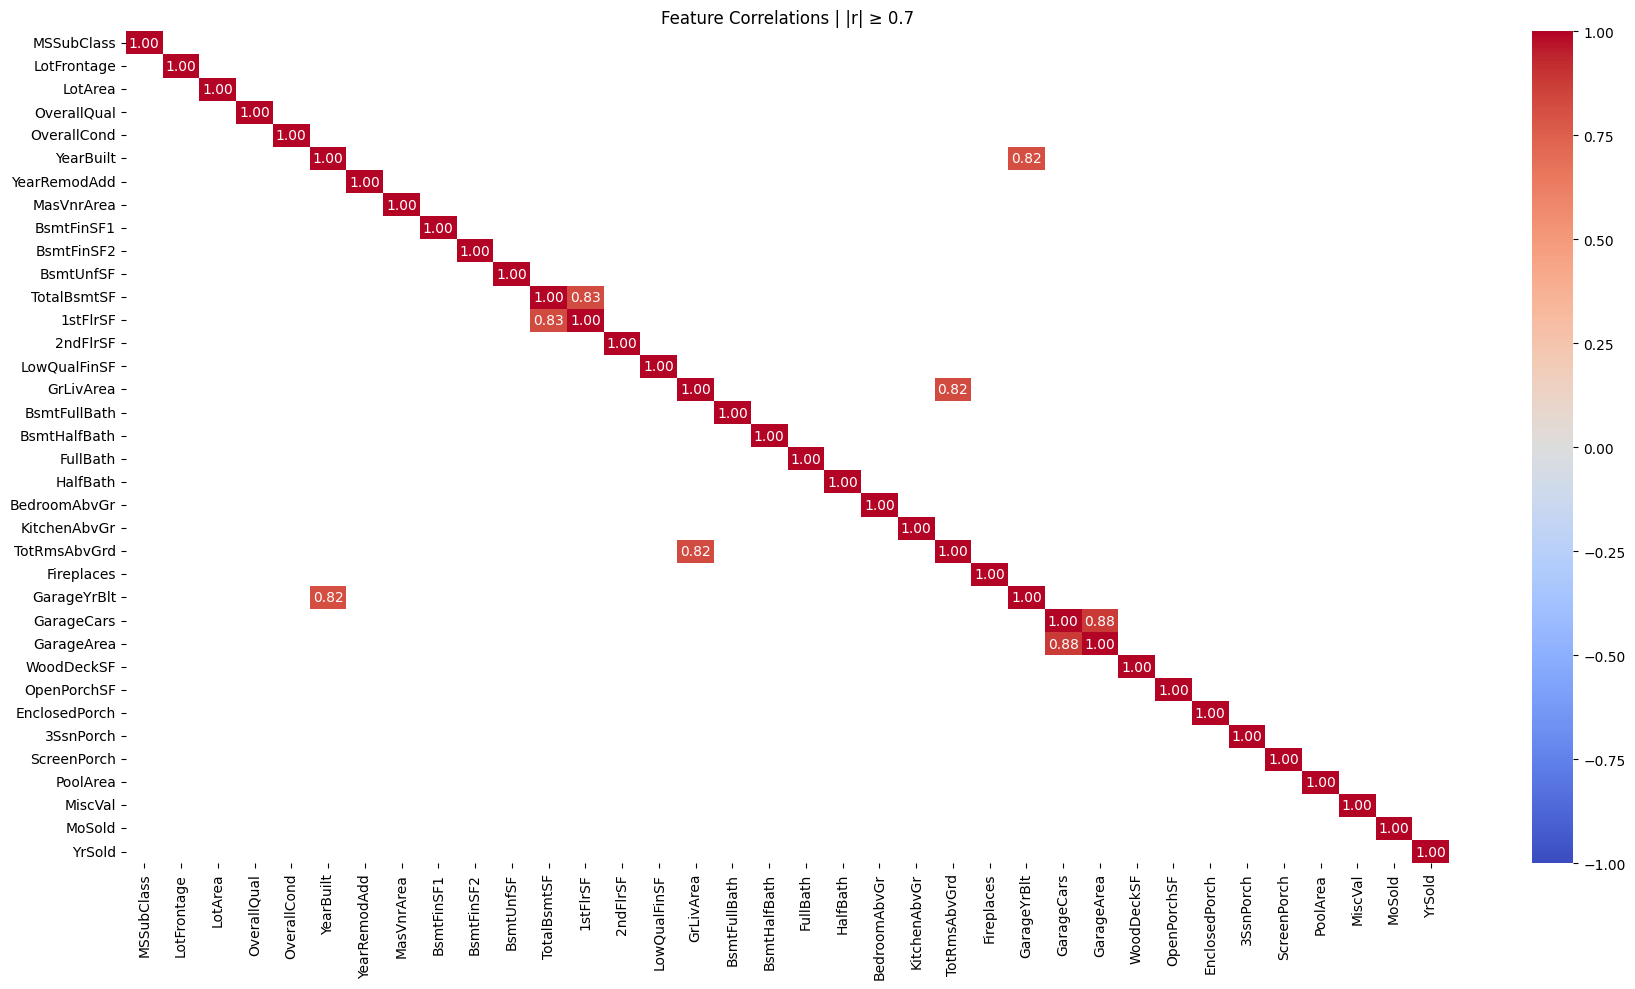

In [10]:

# MULTICOLLINEARITY - HEATMAP


mask = corr_matrix.abs() < threshold

# Ocultar diagonal
#np.fill_diagonal(mask.values, True)

fig, ax = plt.subplots(figsize=(18, 10))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    ax=ax,
    fmt='.2f',
    annot=True,
    mask=mask,
    vmin=-1,
    vmax=1
)

ax.set_title(
    f'Feature Correlations | |r| ≥ {threshold}'
)

fig.tight_layout()
plt.show()


### Save Findings

In [11]:

# SAVE TRACKER

tracker.save()
